## Load reciprocal best blast hits

In [2]:
!sh scripts/interproscan.sh

FATAL:   "-B": executable file not found in $PATH


In [2]:

%%bash
cd ncbi_dataset/data/GCA_965233325.1
singularity exec /cvmfs/singularity.galaxyproject.org/g/f/gffread:0.12.9--hf426362_0 gffread braker.gtf -g *.fna -x cds.faa

In [2]:
import pandas as pd

rbb_df=pd.read_csv("outputs/impatiens_v_coprophila_reciprocal_best_blast_results.csv",index_col=0)
rbb_df

,Bcopro_prot,impatiens_prot
0,XP_037044609.1,bimpatiensg23840.t1
1,XP_037038352.1,bimpatiensg15641.t2
2,XP_037033747.1,bimpatiensg17223.t1
3,XP_037042026.1,bimpatiensg15696.t1
4,XP_037042318.1,bimpatiensg15438.t1
...,...,...
13041,XP_037031244.1,bimpatiensg15120.t1
13042,XP_037041936.1,bimpatiensg24830.t1
13043,XP_080116807.1,bimpatiensg18270.t1
13044,XP_080112729.1,bimpatiensg26131.t1


In [4]:
rbb_map={x:y for x,y in zip(rbb_df.Bcopro_prot,rbb_df.impatiens_prot)}
td=list(set(rbb_map.keys()))

## Obtain dnds for rbbs 

In [52]:
from Bio import SeqIO
import pandas as pd
from Bio import SearchIO
import os
import multiprocessing as mp

In [11]:
%%bash
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/016/920/775/GCA_016920775.1_B2019C/GCA_016920775.1_B2019C_cds_from_genomic.fna.gz
gunzip GCA_016920775.1_B2019C_cds_from_genomic.fna.gz
mv GCA_016920775.1_B2019C_cds_from_genomic.fna ncbi_dataset/data/GCA_016920775.1/GCA_016920775.1_B2019C_cds_from_genomic.fna

--2026-07-04 15:31:34--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/016/920/775/GCA_016920775.1_B2019C/GCA_016920775.1_B2019C_cds_from_genomic.fna.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.11, 130.14.250.12, 2607:f220:41e:250::7, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8174742 (7.8M) [application/x-gzip]
Saving to: ‘GCA_016920775.1_B2019C_cds_from_genomic.fna.gz’

     0K .......... .......... .......... .......... ..........  0% 2.11M 4s
    50K .......... .......... .......... .......... ..........  1% 63.7M 2s
   100K .......... .......... .......... .......... ..........  1% 3.84M 2s
   150K .......... .......... .......... .......... ..........  2% 90.2M 1s
   200K .......... .......... .......... .......... ..........  3% 3.90M 2s
   250K .......... .......... .......... .......... ..........  3% 90.9M 1s
   300K .......... .......... .......... .......... ..........  4%  128M 1s
   350

In [6]:
input_file = open(f"ncbi_dataset/data/GCA_965233325.1/protein.faa")
bo_fastap = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file=open(f"ncbi_dataset/data/GCA_965233325.1/cds.faa")
bo_fastan = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [15]:
bo_fastan2={}
for x in bo_fastan:
    bo_fastan2["bimpatiens"+x]=bo_fastan[x]
bo_fastan=bo_fastan2

In [54]:
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/protein.faa")
bc_fastap = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file=open(f"ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna")
bc_fastan = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [32]:
## for each rbb pair g, align protein seqs with muscle, obtain codon alignments from cds seqs with pal2nal, then run paml M0
def run_paml_pipe(g):

    go=rbb_map[g]

    !mkdir -p pairwise_copro_impatiens_dnds/$g

    ##write protein fasta
    f=open(f'pairwise_copro_impatiens_dnds/{g}/protein_fasta.fa','w')
    f.write(f'>{g}\n')
    f.write(str(bc_fastap[g].seq)+"\n")
    f.write(f'>{go}\n')
    f.write(str(bo_fastap[go].seq)+"\n")
    f.close()

    ##align protein seqs
    !singularity exec /cvmfs/singularity.galaxyproject.org/m/u/muscle:5.1--h9f5acd7_2 muscle -align pairwise_copro_impatiens_dnds/$g/protein_fasta.fa -output pairwise_copro_impatiens_dnds/$g/ali_prot.fasta

    ##write nucleotide fasta 
    input_file = open(f"pairwise_copro_impatiens_dnds/{g}/ali_prot.fasta")
    fa = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

    a=list(fa.keys())
    f=open(f'pairwise_copro_impatiens_dnds/{g}/nuc_fasta.fa','w')
    for ai in a:
        if "XP_" in ai:
            l=bc_fastan.keys()
            k=[x for x in l if ai in x][0]
            f.write(f">{ai}\n")
            f.write(str(bc_fastan[k].seq)+"\n")
        else:
            l=bo_fastan.keys()
            k=[x for x in l if ai in x][0]
            f.write(f">{ai}\n")
            f.write(str(bo_fastan[k].seq)+"\n")
    f.close()

    ##write newick tree
    f=open(f'pairwise_copro_impatiens_dnds/{g}/tree.newick','w')
    a=tuple(a)
    f.write(str(a).replace("'","")+";")
    f.close()

    ##run pal2nal to get codon alignment
    !singularity exec /cvmfs/singularity.galaxyproject.org/p/a/pal2nal:14.1--pl526_0 pal2nal.pl  pairwise_copro_impatiens_dnds/$g/ali_prot.fasta  pairwise_copro_impatiens_dnds/$g/nuc_fasta.fa -output paml -nogap > pairwise_copro_impatiens_dnds/$g/pal2nal

    ##run paml
    !sh scripts/run_paml.sh $g

    return 


In [4]:
import multiprocessing as mp
td=list(set(rbb_map.keys()))
num_processes = 90  
pool = mp.Pool(processes=num_processes)
result = pool.map(run_paml_pipe, td)

In [5]:
# fit null model of neutrality (dnds=1)
def run_paml_null(g):
    !sh scripts/run_paml_null.sh $g
import multiprocessing as mp
num_processes = 90  # Use all available CPU cores
pool = mp.Pool(processes=num_processes)
result = pool.map(run_paml_null, td)
!mv pairwise_copro_impatiens_dnds outputs/

In [5]:
##load dnds results into a dataframe
# !mv pairwise_copro_impatiens_dnds outputs/
import ast
import pandas as pd
dNdS=pd.DataFrame()
fails=[]
for i in td:
    try:
        f=open(f"outputs/pairwise_copro_impatiens_dnds/{i}/m0_paml_output.out","r")
        f=f.readlines()
        dnds=ast.literal_eval([x for x in f if "omega (dN/dS)" in x][0].split("=")[1].strip())
        dNdS.loc[i,"dNdS"]=dnds
        lnl=ast.literal_eval([x for x in f if "lnL" in x][0].split("):")[1].split('      ')[0].strip())
        dNdS.loc[i,"lnL"]=lnl
        dS=ast.literal_eval([x for x in f if "tree length for dS:" in x][0].split('tree length for dS:')[1].strip())
        dNdS.loc[i,'dS']=dS
    except:
        print(i)
        fails.append(i)

XP_080120153.1
XP_037048596.2
XP_080116456.1
XP_037047846.2
XP_080118658.1
XP_080117350.1
XP_080113092.1
XP_080117110.1
XP_080116099.1
XP_080120552.1
XP_037038810.1
XP_080120585.1
XP_080120402.1
XP_037034255.2
XP_080116675.1
XP_037027838.2
XP_037027664.2
XP_037051381.1
XP_037047489.2
XP_037043281.1
XP_037052042.2
XP_080113242.1
XP_037039770.1
XP_080120389.1
XP_037051092.1
XP_080120397.1
XP_080120398.1
XP_037045807.2
XP_080116332.1
XP_080116095.1
XP_080117102.1
XP_080116321.1
XP_080120512.1
XP_037048603.2
XP_037051927.1
XP_037026600.2
XP_037045092.1
XP_037045817.2
XP_080115660.1
XP_037051950.2


In [6]:
fails2=[]
for i in td:
    try:
        f=open(f"outputs/pairwise_copro_impatiens_dnds/{i}/null_m0_paml_output.out","r")
        f=f.readlines()
        lnl=ast.literal_eval([x for x in f if "lnL" in x][0].split("):")[1].split('      ')[0].strip())
        dNdS.loc[i,"null_lnL"]=lnl
    except:
        print(i)
        fails2.append(i)

XP_080120153.1
XP_037048596.2
XP_080116456.1
XP_037047846.2
XP_080118658.1
XP_080117350.1
XP_080113092.1
XP_080117110.1
XP_080116099.1
XP_080120552.1
XP_037038810.1
XP_080120585.1
XP_080120402.1
XP_037034255.2
XP_080116675.1
XP_037027838.2
XP_037027664.2
XP_037051381.1
XP_037047489.2
XP_037043281.1
XP_037052042.2
XP_080113242.1
XP_037039770.1
XP_080120389.1
XP_037051092.1
XP_080120397.1
XP_080120398.1
XP_037045807.2
XP_080116332.1
XP_080116095.1
XP_080117102.1
XP_080116321.1
XP_080120512.1
XP_037048603.2
XP_037051927.1
XP_037026600.2
XP_037045092.1
XP_037045817.2
XP_080115660.1
XP_037051950.2


In [9]:
import numpy as np

In [10]:
import scipy 
from scipy import stats

# rum likelihood ratio test comparing dnds to dnds fixed at 1 
dNdS['2delta(lnL)']=2*(np.array(dNdS['lnL'])-np.array(dNdS['null_lnL']))
for index, row in dNdS.iterrows():
    dNdS.loc[index,"p_val"]=scipy.stats.chi2.sf(row["2delta(lnL)"], 1)

In [11]:
dNdS=dNdS.dropna()

In [12]:
from statsmodels.stats.multitest import multipletests

# Example p-values
p_values = dNdS.p_val

# Perform Benjamini-Hochberg correction
corrected_p_values =list( multipletests(p_values, method='fdr_bh')[1])


In [13]:
dNdS.loc[:,"p_val_corrected"]=corrected_p_values

In [14]:

dNdS.index.name='B.copro'

In [15]:
for index, row in dNdS.iterrows():
    dNdS.loc[index,'B.impatiens']=rbb_map[index]

In [16]:
dNdS=dNdS.loc[:,['B.impatiens','dNdS', 'dS', 'lnL', 'null_lnL', '2delta(lnL)', 'p_val', 'p_val_corrected']]

## Compare dnds by ancestry

In [17]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

In [18]:
di=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col='accession')


In [19]:
import pandas as pd

In [20]:
orphan=list(di[di.type=='orphan'].index)
dipt=list(di[di.type=='dipt'].index)
hgt_genes=set(di[di.tree_HTG].index)

In [21]:
import numpy as np

# Define conditions for each type
conditions = [
    dNdS.index.isin(hgt_genes),   # HGT condition
    dNdS.index.isin(dipt),        # Dipteran condition
    dNdS.index.isin(orphan)       # Orphan condition
]

# Define corresponding choices
choices = ['HGT', 'Dipteran', 'Orphan']

# Assign types based on conditions
dNdS['type'] = np.select(conditions, choices, default='Other')  # Default can be adjusted


In [22]:
dNdS.to_csv('outputs/pairwise_dnds.csv')

In [28]:
import pandas as pd
dNdS=pd.read_csv('outputs/pairwise_dnds.csv')

In [29]:
##return numbers and proportions of genes under purifying selection
def get_stats(df):
    neg=df[(df.p_val_corrected<.05)&(df.dNdS<1)].shape[0]
    pos=df[(df.p_val_corrected<.05)&(df.dNdS>1)].shape[0]
    neut=df.shape[0]-neg-pos
    return df.shape[0], neg, neg/df.shape[0]

In [30]:
dNdS.shape[0]

13006

In [31]:
dNdS[dNdS.type=='HGT'].shape[0]

1047

In [32]:
dNdS=dNdS[dNdS.dS<2]

In [33]:
dNdS.shape[0]

12764

In [34]:
get_stats(dNdS)

(12764, 12709, 0.9956910059542463)

In [35]:
get_stats(dNdS[dNdS.type=='HGT'])

(990, 989, 0.998989898989899)

In [36]:
get_stats(dNdS[dNdS.type=='Dipteran'])

(10535, 10509, 0.9975320360702421)

## Include extracellular localization and rna expression level as covariates

In [37]:
di=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")
di=di[(di.type=='dipt')|(di.tree_HTG)]
dNdS=pd.read_csv('outputs/pairwise_dnds.csv',index_col=0)

In [38]:
dNdS=dNdS[dNdS.dS<2]

In [39]:
import pandas as pd
deeploc=pd.read_csv("outputs/deeploc_results.csv",index_col=0)
deeploc=deeploc.loc[di.index,:]

In [40]:
for index, row in deeploc.iterrows():
    deeploc.loc[index,'gene']=di.loc[index,'gene']

In [41]:
dNdS=dNdS[dNdS.index.isin(di.index)]
for index, row in dNdS.iterrows():
    dNdS.loc[index,'gene']=di.loc[index,'gene']
    

In [42]:
deeploc=deeploc.set_index('gene')


In [43]:
dftpm=pd.read_csv('outputs/mean_tpms.tsv',index_col=0,sep='\t')

In [44]:
dNdS.index=dNdS.gene
for index, row in dNdS.iterrows():
    dNdS.loc[index,'Extracellular']= int('Extracellular' in deeploc.loc[index,'Localizations'])
    dNdS.loc[index,'TPM']= dftpm.loc[index].values[0]

In [45]:
import numpy as np
dNdS["logTPM"]=np.log10(dNdS.TPM+1e-2)

In [46]:
dNdS['HGT']=[int(x in set(di[di.tree_HTG].gene)) for x in dNdS.index]

In [47]:
dNdS['dipt']=[int(x in set(di[di.type=='dipt'].gene)) for x in dNdS.index]

In [48]:
dNdS.index=dNdS.index.astype(str)

In [49]:
di['gene']=di.gene.astype(str)

In [55]:
for index, row in dNdS.iterrows():
    prot=di[di.gene==str(index)].index[0]
    dNdS.loc[index,'cds_len']=len(str(bc_fastan[[x for x in bc_fastan if prot in x][0]].seq))

In [56]:
dNdSi=dNdS[(dNdS.dipt==1)|(dNdS.HGT==1)]

In [57]:
dNdSi[dNdSi.dipt==1].dNdS.median()

0.09045

In [58]:
dNdSi[dNdSi.HGT==1].dNdS.median()

0.14132499999999998

In [59]:
from scipy.stats import mannwhitneyu

print(mannwhitneyu(dNdSi[dNdSi.HGT==0].dNdS,dNdSi[dNdSi.HGT==1].dNdS))

MannwhitneyuResult(statistic=3269159.5, pvalue=3.5761409391147962e-84)


In [60]:
import statsmodels.formula.api as smf 
est = smf.ols(formula='dNdS ~ logTPM+Extracellular+HGT+cds_len', data=dNdSi).fit() 
est.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   dNdS   R-squared:                       0.060
Model:                            OLS   Adj. R-squared:                  0.059
Method:                 Least Squares   F-statistic:                     182.4
Date:                Sun, 16 Aug 2026   Prob (F-statistic):          7.89e-152
Time:                        13:18:20   Log-Likelihood:                 10902.
No. Observations:               11525   AIC:                        -2.179e+04
Df Residuals:                   11520   BIC:                        -2.176e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.1362      0.002     69.672      0.000       0.132       0.140
logTPM           -0.0184      0.001    -16.755      0.000      -0.021      -0.016
Extracellular     0.0309      0.003     12.115      0.000       0.026       0.036
HGT               0.0359      0.003     11.324      0.000       0.030       0.042
cds_len        -1.83e-06   5.27e-07     -3.476      0.001   -2.86e-06   -7.98e-07
==============================================================================
Omnibus:                     4865.603   Durbin-Watson:                   1.996
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            26808.278
Skew:                           1.975   Prob(JB):                         0.00
Kurtosis:                       9.342   Cond. No.                     9.04e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.04e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [61]:
est.pvalues

Intercept        0.000000e+00
logTPM           2.816426e-62
Extracellular    1.404859e-33
HGT              1.422697e-29
cds_len          5.114931e-04
dtype: float64

## Compare dNdS by ancestry

In [62]:
di=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")
di=di[(di.type.isin(['orphan','dipt']))|(di.tree_HTG)]
dNdS=pd.read_csv('outputs/pairwise_dnds.csv',index_col=0)
dNdS=dNdS[dNdS.dS<2]
dNdS=dNdS[dNdS.index.isin(di.index)]
for index, row in dNdS.iterrows():
    dNdS.loc[index,'gene']=di.loc[index,'gene']
dNdS.index=dNdS.gene

In [63]:
agedf=pd.read_csv('outputs/homologs_in_other_sciarids_per_gene.tsv',sep='\t',index_col=0)

for index, row in agedf.iterrows():
    agedf.loc[index,'gene']=di.loc[index,'gene']
agedf.index=agedf.gene  

In [64]:
di.index=di.gene

In [65]:
for index, row in dNdS.iterrows():
    if index in agedf.index:
        dNdS.loc[index,'age']=agedf.loc[index,'phylostratum']
    else:
         dNdS.loc[index,'age']=dNdS.loc[index,'type']

In [66]:
dNdS=dNdS[dNdS.age.isin([3,4,5,'Dipteran','Orphan'])]
dNdS['age']=dNdS['age'].replace({3:'Middle HTG',4:'Old HTG',5:'Old HTG'})

In [67]:
dNdS.dNdS.max()

1.00947

       group1      group2  U_statistic        p_value     n1   n2
0    Dipteran     Old HTG    3070494.0   1.420531e-72  10535  910
1    Dipteran  Middle HTG     188333.5   1.625340e-15  10535   76
2    Dipteran      Orphan     551152.0  4.408731e-177  10535  466
3     Old HTG  Middle HTG      26081.0   3.662851e-04    910   76
4     Old HTG      Orphan      71947.0   1.073360e-89    910  466
5  Middle HTG      Orphan       9140.0   1.307895e-11     76  466


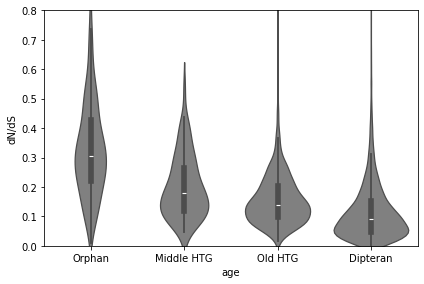

In [68]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

def pairwise_mannwhitney(df, value_col='dNdS', group_col='Ancestry',
                         alternative='two-sided'):
    results = []

    groups = df[group_col].dropna().unique()

    for g1, g2 in itertools.combinations(groups, 2):
        x = df.loc[df[group_col] == g1, value_col].dropna()
        y = df.loc[df[group_col] == g2, value_col].dropna()

        if len(x) > 0 and len(y) > 0:
            stat, p = mannwhitneyu(x, y, alternative=alternative)
        else:
            stat, p = float('nan'), float('nan')

        results.append({
            'group1': g1,
            'group2': g2,
            'U_statistic': stat,
            'p_value': p,
            'n1': len(x),
            'n2': len(y)
        })

    return pd.DataFrame(results)


def add_pairwise_pvalues(ax, results, order, y_start=1.02, y_step=0.08):
    """
    Add p-value brackets for all pairwise comparisons.

    ax      : matplotlib axis
    results : output from pairwise_mannwhitney()
    order   : category order used in the plot
    """
    x_positions = {group: i for i, group in enumerate(order)}

    for i, row in results.iterrows():
        g1 = row['group1']
        g2 = row['group2']
        p = row['p_value']

        x1 = x_positions[g1]
        x2 = x_positions[g2]

        y = y_start + i * y_step
        h = 0.025

        ax.plot(
            [x1, x1, x2, x2],
            [y, y + h, y + h, y],
            lw=1.2,
            color='black'
        )

        ax.text(
            (x1 + x2) / 2,
            y + h,
            f"p = {p:.3g}",
            ha='center',
            va='bottom',
            fontsize=10
        )


# Define the order explicitly
order = ['Orphan', 'Middle HTG', 'Old HTG', 'Dipteran']

# Calculate pairwise Mann-Whitney tests
mw_results = pairwise_mannwhitney(
    dNdS,
    value_col='dNdS',
    group_col='age'
)

print(mw_results)

# Plot
plt.figure(figsize=(6, 4))

ax = sns.violinplot(
    data=dNdS,
    x='age',
    y='dNdS',
    order=order,
    color='grey'
)

plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=order
)

plt.ylabel('dN/dS')

# # Extend ylim to make room for p-values
# plt.ylim(0, 1.65)

# # Add p-value annotations
# add_pairwise_pvalues(
#     ax,
#     mw_results,
#     order=order,
#     y_start=1.05,
#     y_step=0.09
# )

plt.tight_layout()
plt.ylim(0,.8)
plt.savefig(
    'figures/dNdS_pairwise_by_phylostratum.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()

In [12]:
summary_df = (
    dNdS
    .dropna(subset=['dNdS', 'age'])
    .groupby('age')
    .agg(
        median_dNdS=('dNdS', 'median'),
        n_genes=('dNdS', 'size')
    )
    .reset_index()
)
summary_df

,age,median_dNdS,n_genes
0,Dipteran,0.090450,10535
1,Middle HTG,0.179520,76
2,Old HTG,0.139865,910
3,Orphan,0.304195,466
